# 基于预训练 CNN 的图像分类与聚类
## CIFAR-10 / CIFAR-100 共享 ResNet18 Backbone 实验

**课程作业**：进阶实验——预训练 CNN 分类与聚类

本 Notebook 完整执行以下流程：

1. 读取并探索 CIFAR-10 与 CIFAR-100；
2. 统一预处理、分层划分训练/验证/测试集；
3. 加载 ImageNet 预训练 ResNet18，共享 Backbone，分别训练 10 类与 100 类分类头（Hugging Face `Trainer`）；
4. 在测试集上计算 Accuracy、混淆矩阵等分类指标；
5. 提取 CNN 512 维特征，调用 sklearn `MiniBatchKMeans` 完成 K=10 / K=100 聚类；
6. 计算 ARI、NMI 等聚类指标，完成 PCA / t-SNE 可视化与样本展示；
7. 对两个数据集的分类与聚类结果进行对比分析。

> 所有数值、图表和日志均由本 Notebook 真实运行产生。运行环境为 CPU（无 GPU），因此在官方训练集中按类别分层抽取 5,000 张用于训练、1,000 张用于验证；官方 10,000 张测试集完整保留且不参与训练。

In [1]:
import os, sys, json, time, platform, random, warnings, subprocess
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("USE_FLAX", "0")
os.environ.setdefault("OMP_NUM_THREADS", "4")
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from IPython.display import display, Image, Markdown
from src import datasets as ds
from src import visualization as vis
from src.models import build_model, count_parameters, architecture_table, FeatureBackbone
from src.training import train_classifier, evaluate_test, save_predictions_csv
from src.feature_extraction import extract_features, save_feature_bundle, load_feature_bundle
from src.clustering import run_clustering

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
vis.setup_style()

# ------------------------------------------------------------------
# 实验规模配置：CPU 环境下使用分层子集控制时间；测试集始终为完整 10,000 张
# ------------------------------------------------------------------
QUICK_TEST = False

if QUICK_TEST:
    IMG_SIZE = 64
    EPOCHS = 1
    TRAIN_PER_CLASS = {"cifar10": 100, "cifar100": 20}
    VAL_PER_CLASS = {"cifar10": 20, "cifar100": 10}
    FROZEN_FEATURE_SIZE = 128
    VIS_SAMPLE = 600
    LOGGING_STEPS = 10
else:
    IMG_SIZE = 96
    EPOCHS = 3
    TRAIN_PER_CLASS = {"cifar10": 500, "cifar100": 50}
    VAL_PER_CLASS = {"cifar10": 100, "cifar100": 10}
    FROZEN_FEATURE_SIZE = 224
    VIS_SAMPLE = 5000
    LOGGING_STEPS = 50

BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
LR = 3e-4
DATA_DIR = ROOT / "data" / "raw"
CKPT_DIR = ROOT / "checkpoints"
METRICS_DIR = ROOT / "results" / "metrics"
FIG_DIR = ROOT / "results" / "figures"
FEAT_DIR = ROOT / "results" / "features"
LOG_DIR = ROOT / "results" / "logs"
for p in (CKPT_DIR, METRICS_DIR, FIG_DIR, FEAT_DIR, LOG_DIR):
    p.mkdir(parents=True, exist_ok=True)

def show(path, width=1100):
    display(Image(filename=str(path), width=width))
    plt.close("all")

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("torchvision :", __import__("torchvision").__version__)
print("transformers:", __import__("transformers").__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("NumPy/Pandas:", np.__version__, "/", pd.__version__)
print("CPU         :", platform.processor(), "| logical cores:", os.cpu_count())
print("Device      :", DEVICE, "| CUDA available:", torch.cuda.is_available())
print("Config      : img=%d, epochs=%d, train/class=%s, val/class=%s, frozen_feature=%d"
      % (IMG_SIZE, EPOCHS, TRAIN_PER_CLASS, VAL_PER_CLASS, FROZEN_FEATURE_SIZE))

Python      : 3.12.4
PyTorch     : 2.5.0+cpu
torchvision : 0.20.0+cpu
transformers: 4.57.3
scikit-learn: 1.6.0
NumPy/Pandas: 1.26.4 / 2.3.0
CPU         : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | logical cores: 16
Device      : cpu | CUDA available: False
Config      : img=96, epochs=3, train/class={'cifar10': 500, 'cifar100': 50}, val/class={'cifar10': 100, 'cifar100': 10}, frozen_feature=224


## 1. 实验目的

- 使用同一套 ImageNet 预训练 ResNet18 Backbone，为 CIFAR-10 和 CIFAR-100 分别构建分类头，完成迁移学习；
- 使用 Hugging Face `Trainer` 完成训练循环、反向传播、验证、日志与权重保存；
- 使用 CNN 提取的 512 维特征，直接调用 sklearn 的 `MiniBatchKMeans` 完成无监督聚类（K=10 / K=100）；
- 使用 Accuracy、混淆矩阵、ARI、NMI、PCA、t-SNE 等统一指标，比较两个数据集的分类与聚类难度；
- 分析类别数量增加对分类与聚类性能的影响。

**实验环境**：Windows + CPU（Intel 16 逻辑核，16 GB 内存），Python 3.12，PyTorch 2.5.0，torchvision 0.20.0，transformers 4.57.3，scikit-learn 1.6.0。由于没有 GPU，训练轮数、批大小和特征输入尺寸均按 CPU 条件设置，测试集保持完整。

## 2. 数据集读取与探索

CIFAR-10 与 CIFAR-100 均包含 60,000 张 32×32 彩色图像，其中官方训练集 50,000 张、测试集 10,000 张。两者图像完全相同，但标签粒度不同：

- **CIFAR-10**：10 个互斥类别，每类训练 5,000 张、测试 1,000 张；
- **CIFAR-100**：100 个细类，每类训练 500 张、测试 100 张，另有 20 个超类。

数据来自官方 CIFAR 数据集（Hugging Face 镜像的逐字节副本），首次运行会自动下载并转换为 `data/raw/*.npz`。

In [2]:
required = [DATA_DIR / f"{name}_{split}.npz" for name in ("cifar10", "cifar100")
            for split in ("train", "test")]
if not all(p.exists() for p in required):
    print("未检测到本地数据，开始下载并转换 ...")
    subprocess.run([sys.executable, str(ROOT / "scripts" / "download_cifar_parquet.py")], check=True)
for p in required:
    print(f"{p.relative_to(ROOT)}  {p.stat().st_size/1e6:8.1f} MB")

data\raw\cifar10_train.npz     141.4 MB
data\raw\cifar10_test.npz      28.3 MB
data\raw\cifar100_train.npz     140.3 MB
data\raw\cifar100_test.npz      28.1 MB


In [3]:
# 构建两个数据集的分层子集（测试集完整保留）
bundles = {}
for name in ("cifar10", "cifar100"):
    bundles[name] = ds.build_datasets(
        name, img_size=IMG_SIZE,
        train_per_class=TRAIN_PER_CLASS[name],
        val_per_class=VAL_PER_CLASS[name],
        seed=SEED,
    )

rows = []
for name, b in bundles.items():
    rows.append({
        "数据集": b.info["display_name"],
        "类别数": b.info["num_classes"],
        "原始训练集": b.info["official_train_size"],
        "训练集": b.info["train_size"],
        "验证集": b.info["val_size"],
        "测试集": b.info["test_size"],
        "图像尺寸": "32×32×3",
        "输入尺寸": f"{IMG_SIZE}×{IMG_SIZE}",
    })
display(pd.DataFrame(rows).set_index("数据集"))
ds.save_dataset_info(list(bundles.values()), METRICS_DIR / "dataset_info.json")

spec10 = bundles["cifar10"].spec
spec100 = bundles["cifar100"].spec
print("CIFAR-10 类别：", "、".join(f"{i}:{n}" for i, n in enumerate(spec10.class_names)))
print("CIFAR-100 前 20 类：", "、".join(f"{i}:{n}" for i, n in enumerate(spec100.class_names[:20])))
print("CIFAR-100 类别总数：", len(spec100.class_names))

,类别数,原始训练集,训练集,验证集,测试集,图像尺寸,输入尺寸
数据集,,,,,,,
CIFAR-10,10,50000,5000,1000,10000,32×32×3,96×96
CIFAR-100,100,50000,5000,1000,10000,32×32×3,96×96


CIFAR-10 类别： 0:airplane、1:automobile、2:bird、3:cat、4:deer、5:dog、6:frog、7:horse、8:ship、9:truck
CIFAR-100 前 20 类： 0:apple、1:aquarium_fish、2:baby、3:bear、4:beaver、5:bed、6:bee、7:beetle、8:bicycle、9:bottle、10:bowl、11:boy、12:bridge、13:bus、14:butterfly、15:camel、16:can、17:castle、18:caterpillar、19:cattle
CIFAR-100 类别总数： 100


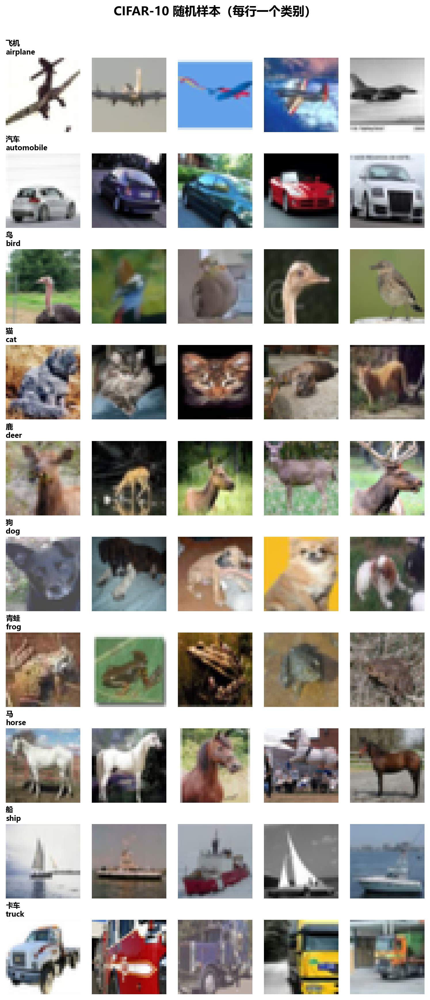

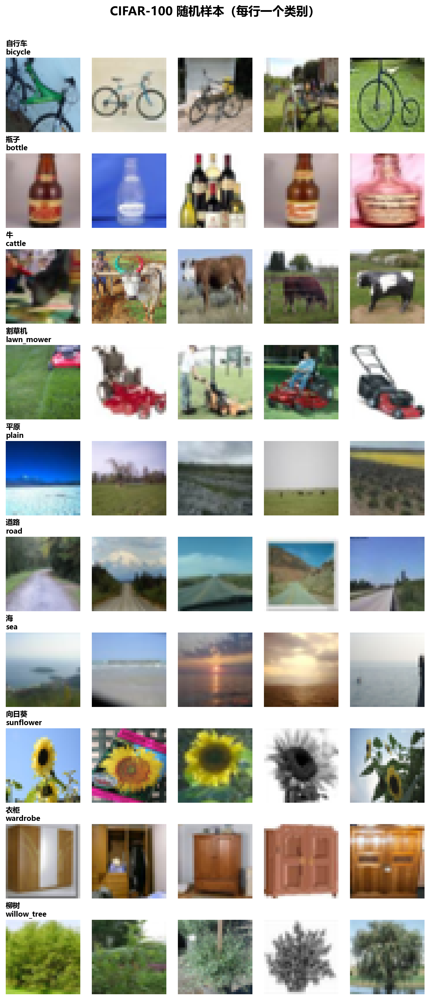

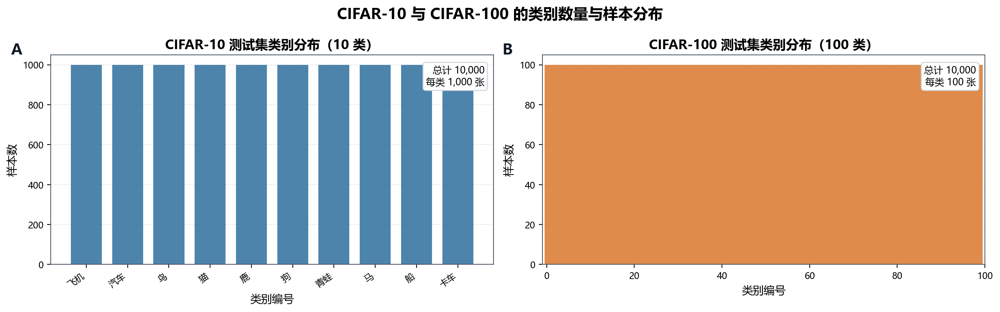

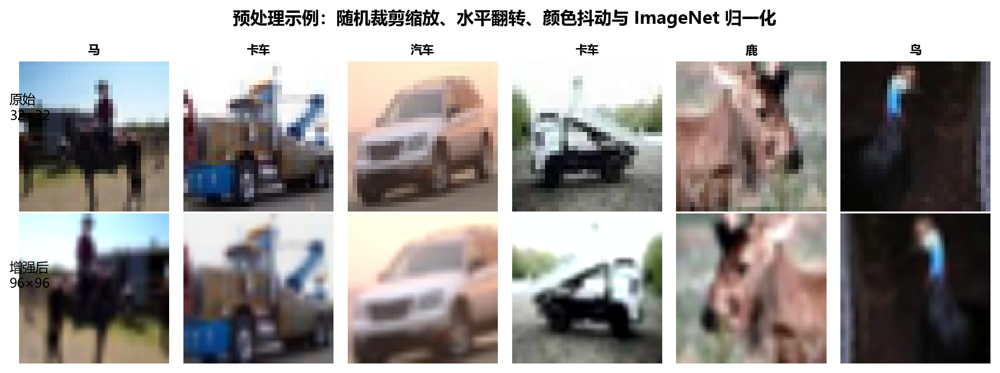

In [4]:
# 随机样本、类别分布、预处理前后对比
p = vis.plot_dataset_samples(bundles["cifar10"].images_train, bundles["cifar10"].labels_train,
                             spec10.class_names, spec10.class_names_zh,
                             FIG_DIR / "01_cifar10_samples.png", "CIFAR-10",
                             per_class=5, max_classes=10, seed=SEED)
show(p, 950)

p = vis.plot_dataset_samples(bundles["cifar100"].images_train, bundles["cifar100"].labels_train,
                             spec100.class_names, spec100.class_names_zh,
                             FIG_DIR / "02_cifar100_samples.png", "CIFAR-100",
                             per_class=5, max_classes=10, seed=SEED)
show(p, 950)

p = vis.plot_class_distribution(bundles["cifar10"].info, bundles["cifar100"].info,
                                FIG_DIR / "03_class_distribution.png")
show(p, 1100)

p = vis.plot_preprocessing(bundles["cifar10"].images_train, bundles["cifar10"].labels_train,
                           spec10.class_names_zh, ds.build_transforms(IMG_SIZE, True),
                           FIG_DIR / "04_preprocessing.png")
show(p, 1050)

### 2.1 训练 / 验证 / 测试划分

- 训练集与验证集均从**官方训练集**中按类别分层抽取，二者索引互斥；
- 测试集使用官方 10,000 张测试图像，完整保留，**不参与任何训练、调参或模型选择**；
- 两个数据集的训练集均为 5,000 张（CIFAR-10 每类 500 张，CIFAR-100 每类 50 张），验证集均为 1,000 张，从而在相同训练样本量下比较分类与聚类难度；
- 预处理：随机裁剪缩放至 96×96、随机水平翻转、轻度颜色抖动；验证/测试仅 Resize 到 96×96；
- 归一化：使用 ImageNet 均值 `(0.485, 0.456, 0.406)` 与标准差 `(0.229, 0.224, 0.225)`，与预训练权重的输入分布保持一致。

> 将 32×32 放大到 96×96 是在“保留预训练感受野/语义特征”和“CPU 可承受的计算量”之间的折中。若直接使用 32×32，ResNet18 的 stride-32 特征图仅 1×1，空间信息损失较大；若使用 224×224，CPU 训练时间约增加 5 倍。

In [5]:
rows = []
for name, b in bundles.items():
    rows.append({
        "数据集": b.info["display_name"],
        "训练集": b.info["train_size"],
        "验证集": b.info["val_size"],
        "测试集": b.info["test_size"],
        "训练集每类": b.info["train_per_class"],
        "验证集每类": b.info["val_per_class"],
        "训练/验证索引交集": len(np.intersect1d(b.train_indices, b.val_indices)),
        "测试集参与训练": "否",
    })
display(pd.DataFrame(rows).set_index("数据集"))

x, y = bundles["cifar10"].train[0]["pixel_values"], bundles["cifar10"].train[0]["labels"]
print("单个训练样本张量：", tuple(x.shape), "| 均值 %.3f | 标准差 %.3f" % (float(x.mean()), float(x.std())))
print("归一化使用 ImageNet mean/std；训练增强后的像素范围约为 [-2.12, 2.20]。")

,训练集,验证集,测试集,训练集每类,验证集每类,训练/验证索引交集,测试集参与训练
数据集,,,,,,,
CIFAR-10,5000,1000,10000,500,100,0,否
CIFAR-100,5000,1000,10000,50,10,0,否


单个训练样本张量： (3, 96, 96) | 均值 -0.389 | 标准差 0.940
归一化使用 ImageNet mean/std；训练增强后的像素范围约为 [-2.12, 2.20]。


## 3. ResNet18 模型结构

采用 torchvision 的 ResNet18（ImageNet-1K 预训练），去掉原始 1000 类全连接层，保留 4 个 Stage 与全局平均池化，得到 512 维图像特征。随后接两个数据集专属分类头：

- CIFAR-10 头：`Dropout(0.2) + Linear(512 → 10)`；
- CIFAR-100 头：`Dropout(0.2) + Linear(512 → 100)`。

`task_ids` 用于在同一个模型中选择使用哪个头。两个数据集各自从**同一份 ImageNet 预训练权重**初始化、分别训练并分别保存权重，因此 Backbone 的预训练知识是共享的，而分类头是数据集专属的。

ResNet18 双头模型参数量： 11,232,942 (11.23 M)


,stage,module,output
0,输入,预处理,3×H×W (H=W=输入尺寸)
1,Stem,"7×7 Conv, stride 2 + BN + ReLU + 3×3 MaxPool",64×H/4×W/4
2,Layer 1,"2 × BasicBlock, 64 channels",64×H/4×W/4
3,Layer 2,"2 × BasicBlock, 128 channels, stride 2",128×H/8×W/8
4,Layer 3,"2 × BasicBlock, 256 channels, stride 2",256×H/16×W/16
5,Layer 4,"2 × BasicBlock, 512 channels, stride 2",512×H/32×W/32
6,Pooling,Global Average Pooling,512
7,CIFAR-10 头,Dropout(0.2) + Linear(512→10),10
8,CIFAR-100 头,Dropout(0.2) + Linear(512→100),100


CIFAR-10 头输出： (2, 10)
CIFAR-100 头输出： (2, 100)


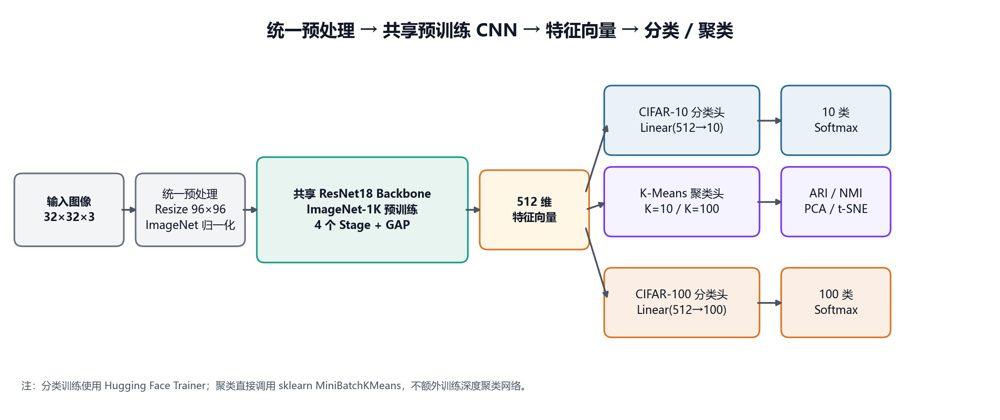

In [6]:
model = build_model(pretrained=True, device=DEVICE)
params = count_parameters(model)
print("ResNet18 双头模型参数量：", f"{params['total']:,}", f"({params['total_million']} M)")
display(pd.DataFrame(architecture_table(model)))

with torch.no_grad():
    demo = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
    out10 = model(demo, task_ids=torch.zeros(2, dtype=torch.long))
    out100 = model(demo, task_ids=torch.ones(2, dtype=torch.long))
print("CIFAR-10 头输出：", tuple(out10.logits.shape))
print("CIFAR-100 头输出：", tuple(out100.logits.shape))

p = vis.plot_framework(FIG_DIR / "00_framework.png", img_size=IMG_SIZE)
show(p, 1150)
del model, demo, out10, out100

## 4. CIFAR-10 分类训练（Hugging Face Trainer）

训练由 `transformers.Trainer` 全权负责：前向/反向传播、AdamW 更新、余弦学习率、逐 epoch 验证、最佳模型保存与日志记录，**没有手写训练循环**。

| 超参数 | 取值 |
|---|---|
| 预训练权重 | ImageNet-1K ResNet18 |
| 输入尺寸 | 96×96 |
| 训练 / 验证 | 5,000 / 1,000 |
| Batch size | 32 |
| 训练轮数 | 3 |
| 优化器 | AdamW（Trainer 内置） |
| 初始学习率 | 3×10⁻⁴ |
| 权重衰减 | 0.01 |
| 学习率调度 | Cosine + 10% warmup |
| 评估策略 | 每个 epoch 在验证集评估，保存最佳模型 |


=== Training CIFAR-10 ===
train=5000 val=1000 test=10000 img_size=96 epochs=3 batch=32 lr=0.0003


[    1.8s] [cifar10] step    1/471 | epoch  0.01 | train_loss 2.8336 | lr 0.00e+00


{'loss': 2.8336, 'grad_norm': 19.519784927368164, 'learning_rate': 0.0, 'epoch': 0.006369426751592357}


[   58.1s] [cifar10] step   50/471 | epoch  0.32 | train_loss 1.6396 | lr 3.00e-04


{'loss': 1.6396, 'grad_norm': 11.752801895141602, 'learning_rate': 0.00029999586306899616, 'epoch': 0.3184713375796178}


[  116.1s] [cifar10] step  100/471 | epoch  0.64 | train_loss 0.8472 | lr 2.89e-04


... (22 outputs left out)

[  605.7s] [cifar10] eval @ epoch  3.00 | eval_loss 0.3692 | acc 0.8840


{'eval_loss': 0.36924445629119873, 'eval_accuracy': 0.884, 'eval_top3_accuracy': 0.983, 'eval_macro_f1': 0.8832038012900426, 'eval_weighted_f1': 0.8832038012900426, 'eval_log_loss': 0.3692444233619904, 'eval_runtime': 10.9293, 'eval_samples_per_second': 91.497, 'eval_steps_per_second': 1.464, 'epoch': 3.0}
[cifar10] validation: {"eval_loss": 0.36924445629119873, "eval_accuracy": 0.884, "eval_top3_accuracy": 0.983, "eval_macro_f1": 0.8832038012900426, "eval_weighted_f1": 0.8832038012900426, "eval_log_loss": 0.3692444233619904, "eval_runtime": 10.9293, "eval_samples_per_second": 91.497, "eval_steps_per_second": 1.464, "epoch": 3.0}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_top3_accuracy,eval_macro_f1,eval_weighted_f1,eval_log_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
3,0.8389,9.583644,0.000260,0.955414,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,1.000000,157,0.741181,0.769,0.934,0.765232,0.765232,0.741181,10.7636,92.906,1.486,NaN,NaN,NaN,NaN,NaN
5,0.6188,9.422256,0.000215,1.273885,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.4989,10.047857,0.000162,1.592357,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.4888,9.186139,0.000107,1.910828,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,2.000000,314,0.419898,0.860,0.979,0.859595,0.859595,0.419898,10.3633,96.495,1.544,NaN,NaN,NaN,NaN,NaN
9,0.3425,5.200672,0.000057,2.229299,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,0.2833,5.025116,0.000021,2.547771,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,0.2843,5.800103,0.000002,2.866242,450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,NaN,NaN,NaN,3.000000,471,0.369244,0.884,0.983,0.883204,0.883204,0.369244,11.9275,83.840,1.341,NaN,NaN,NaN,NaN,NaN


{
  "dataset": "cifar10",
  "epochs": 3,
  "batch_size": 32,
  "eval_batch_size": 64,
  "learning_rate": 0.0003,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "lr_scheduler": "cosine",
  "optimizer": "AdamW",
  "img_size": 96,
  "train_size": 5000,
  "val_size": 1000,
  "test_size": 10000,
  "elapsed_sec": 594.69,
  "train_runtime_sec": 594.17,
  "train_samples_per_second": 25.25,
  "best_checkpoint": "checkpoints\\cifar10\\trainer\\checkpoint-471",
  "best_metric": 0.884,
  "total_steps": 471,
  "final_train_loss": 0.6343312683631913,
  "val_metrics": {
    "eval_loss": 0.36924445629119873,
    "eval_accuracy": 0.884,
    "eval_top3_accuracy": 0.983,
    "eval_macro_f1": 0.8832038012900426,
    "eval_weighted_f1": 0.8832038012900426,
    "eval_log_loss": 0.3692444233619904,
    "eval_runtime": 10.9293,
    "eval_samples_per_second": 91.497,
    "eval_steps_per_second": 1.464,
    "epoch": 3.0
  },
  "log_history_records": 15
}


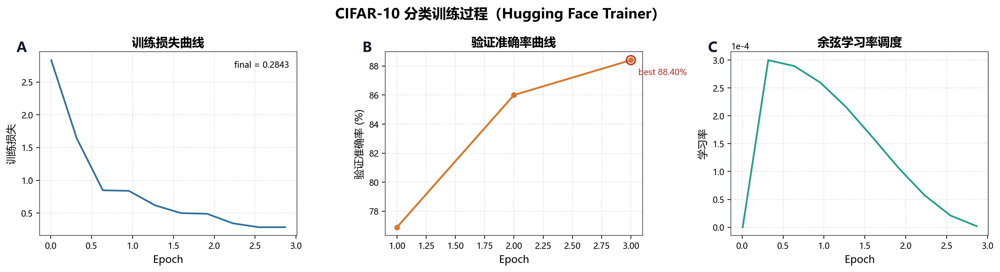

In [7]:
c10 = train_classifier(
    bundles["cifar10"], CKPT_DIR / "cifar10", METRICS_DIR,
    epochs=EPOCHS, batch_size=BATCH_SIZE, eval_batch_size=EVAL_BATCH_SIZE,
    lr=LR, logging_steps=LOGGING_STEPS, seed=SEED,
)
display(c10.log_history.tail(12))
print(json.dumps(c10.history, ensure_ascii=False, indent=2))

p = vis.plot_training_curves(c10.log_history, "CIFAR-10", FIG_DIR / "05_cifar10_training_curves.png")
show(p)

,CIFAR-10
dataset,cifar10
display_name,CIFAR-10
num_classes,10
test_size,10000
accuracy,0.8754
top3_accuracy,0.9802
top5_accuracy,0.9956
macro_f1,0.874178
weighted_f1,0.874178
macro_precision,0.875058


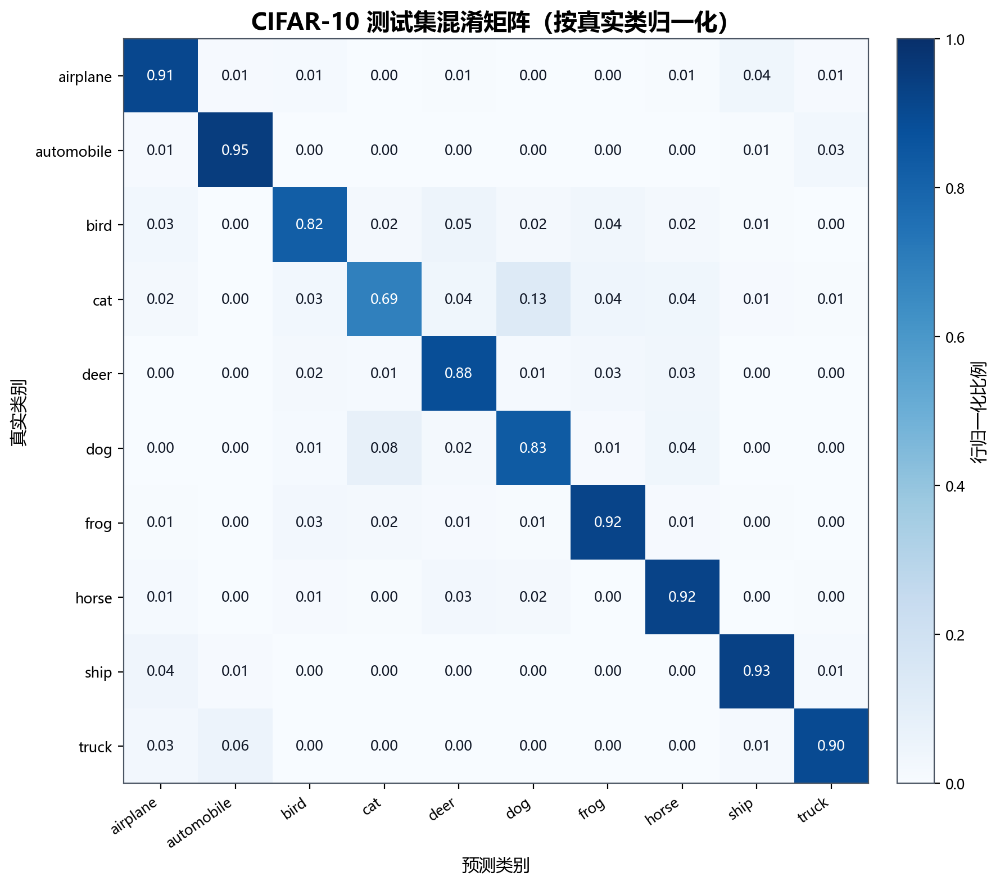

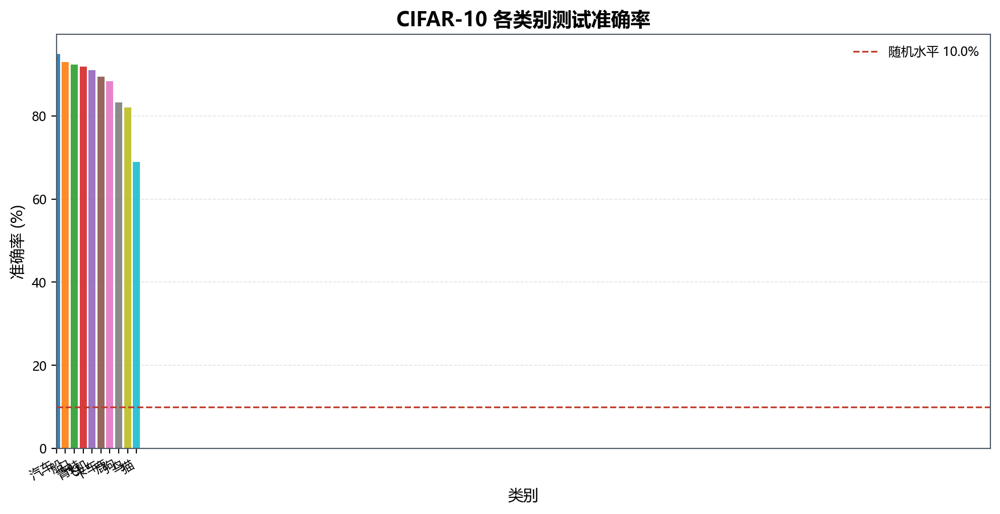

In [8]:
c10_metrics = evaluate_test(c10.trainer, bundles["cifar10"], METRICS_DIR)
save_predictions_csv(bundles["cifar10"], METRICS_DIR)
display(pd.DataFrame([c10_metrics]).T.rename(columns={0: "CIFAR-10"}))

cm10 = np.load(METRICS_DIR / "cifar10_confusion_matrix.npy")
p = vis.plot_confusion_matrix(cm10, spec10.class_names, FIG_DIR / "06_cifar10_confusion_matrix.png",
                              "CIFAR-10", normalize=True)
show(p, 900)

report10 = pd.read_csv(METRICS_DIR / "cifar10_classification_report.csv")
p = vis.plot_per_class_accuracy(report10, FIG_DIR / "07_cifar10_per_class_accuracy.png", "CIFAR-10")
show(p, 950)

## 5. CIFAR-100 分类训练（Hugging Face Trainer）

训练配置与 CIFAR-10 完全一致，仅将分类头替换为 100 维，训练集改为 CIFAR-100 的分层 5,000 张（每类 50 张）。这样可以直接比较“相同 Backbone、相同训练样本量、不同类别数”下的分类难度。


=== Training CIFAR-100 ===
train=5000 val=1000 test=10000 img_size=96 epochs=3 batch=32 lr=0.0003


[    3.1s] [cifar100] step    1/471 | epoch  0.01 | train_loss 5.0188 | lr 0.00e+00


{'loss': 5.0188, 'grad_norm': 18.512393951416016, 'learning_rate': 0.0, 'epoch': 0.006369426751592357}


[   65.5s] [cifar100] step   50/471 | epoch  0.32 | train_loss 4.4650 | lr 3.00e-04


{'loss': 4.465, 'grad_norm': 13.556098937988281, 'learning_rate': 0.00029999586306899616, 'epoch': 0.3184713375796178}


[  140.1s] [cifar100] step  100/471 | epoch  0.64 | train_loss 3.1612 | lr 2.89e-04


... (22 outputs left out)

[  660.9s] [cifar100] eval @ epoch  3.00 | eval_loss 1.4247 | acc 0.6040


{'eval_loss': 1.424667239189148, 'eval_accuracy': 0.604, 'eval_top3_accuracy': 0.822, 'eval_macro_f1': 0.5938733288326167, 'eval_weighted_f1': 0.5938733288326167, 'eval_top5_accuracy': 0.887, 'eval_log_loss': 1.424667268033123, 'eval_runtime': 11.5991, 'eval_samples_per_second': 86.213, 'eval_steps_per_second': 1.379, 'epoch': 3.0}
[cifar100] validation: {"eval_loss": 1.424667239189148, "eval_accuracy": 0.604, "eval_top3_accuracy": 0.822, "eval_macro_f1": 0.5938733288326167, "eval_weighted_f1": 0.5938733288326167, "eval_top5_accuracy": 0.887, "eval_log_loss": 1.424667268033123, "eval_runtime": 11.5991, "eval_samples_per_second": 86.213, "eval_steps_per_second": 1.379, "epoch": 3.0}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_top3_accuracy,eval_macro_f1,eval_weighted_f1,eval_top5_accuracy,eval_log_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
3,2.4208,12.700728,0.000260,0.955414,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,1.000000,157,2.143511,0.417,0.683,0.390643,0.390643,0.786,2.143511,14.7562,67.768,1.084,NaN,NaN,NaN,NaN,NaN
5,1.8528,11.349524,0.000215,1.273885,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1.7035,11.233256,0.000162,1.592357,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1.5450,11.240040,0.000107,1.910828,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,2.000000,314,1.515739,0.586,0.808,0.575079,0.575079,0.872,1.515739,10.2618,97.449,1.559,NaN,NaN,NaN,NaN,NaN
9,1.1954,8.497976,0.000057,2.229299,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,1.0369,8.741533,0.000021,2.547771,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,1.0423,10.608514,0.000002,2.866242,450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,NaN,NaN,NaN,3.000000,471,1.424667,0.604,0.822,0.593873,0.593873,0.887,1.424667,10.2786,97.289,1.557,NaN,NaN,NaN,NaN,NaN


{
  "dataset": "cifar100",
  "epochs": 3,
  "batch_size": 32,
  "eval_batch_size": 64,
  "learning_rate": 0.0003,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "lr_scheduler": "cosine",
  "optimizer": "AdamW",
  "img_size": 96,
  "train_size": 5000,
  "val_size": 1000,
  "test_size": 10000,
  "elapsed_sec": 649.19,
  "train_runtime_sec": 648.0,
  "train_samples_per_second": 23.15,
  "best_checkpoint": "checkpoints\\cifar100\\trainer\\checkpoint-471",
  "best_metric": 0.604,
  "total_steps": 471,
  "final_train_loss": 2.003912004442478,
  "val_metrics": {
    "eval_loss": 1.424667239189148,
    "eval_accuracy": 0.604,
    "eval_top3_accuracy": 0.822,
    "eval_macro_f1": 0.5938733288326167,
    "eval_weighted_f1": 0.5938733288326167,
    "eval_top5_accuracy": 0.887,
    "eval_log_loss": 1.424667268033123,
    "eval_runtime": 11.5991,
    "eval_samples_per_second": 86.213,
    "eval_steps_per_second": 1.379,
    "epoch": 3.0
  },
  "log_history_records": 15
}


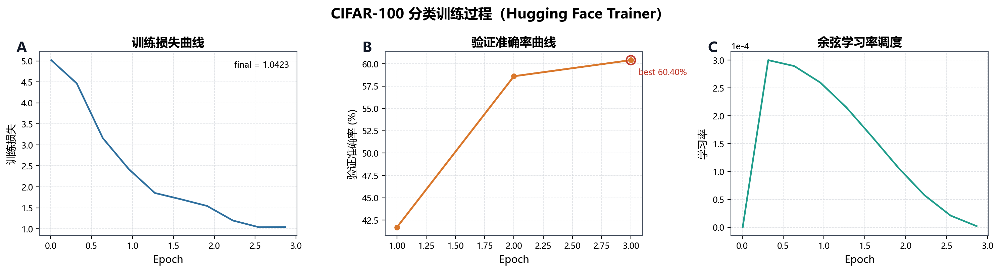

In [9]:
c100 = train_classifier(
    bundles["cifar100"], CKPT_DIR / "cifar100", METRICS_DIR,
    epochs=EPOCHS, batch_size=BATCH_SIZE, eval_batch_size=EVAL_BATCH_SIZE,
    lr=LR, logging_steps=LOGGING_STEPS, seed=SEED,
)
display(c100.log_history.tail(12))
print(json.dumps(c100.history, ensure_ascii=False, indent=2))

p = vis.plot_training_curves(c100.log_history, "CIFAR-100", FIG_DIR / "08_cifar100_training_curves.png")
show(p)

,CIFAR-100
dataset,cifar100
display_name,CIFAR-100
num_classes,100
test_size,10000
accuracy,0.6008
top3_accuracy,0.814
top5_accuracy,0.8851
macro_f1,0.594908
weighted_f1,0.594908
macro_precision,0.602778


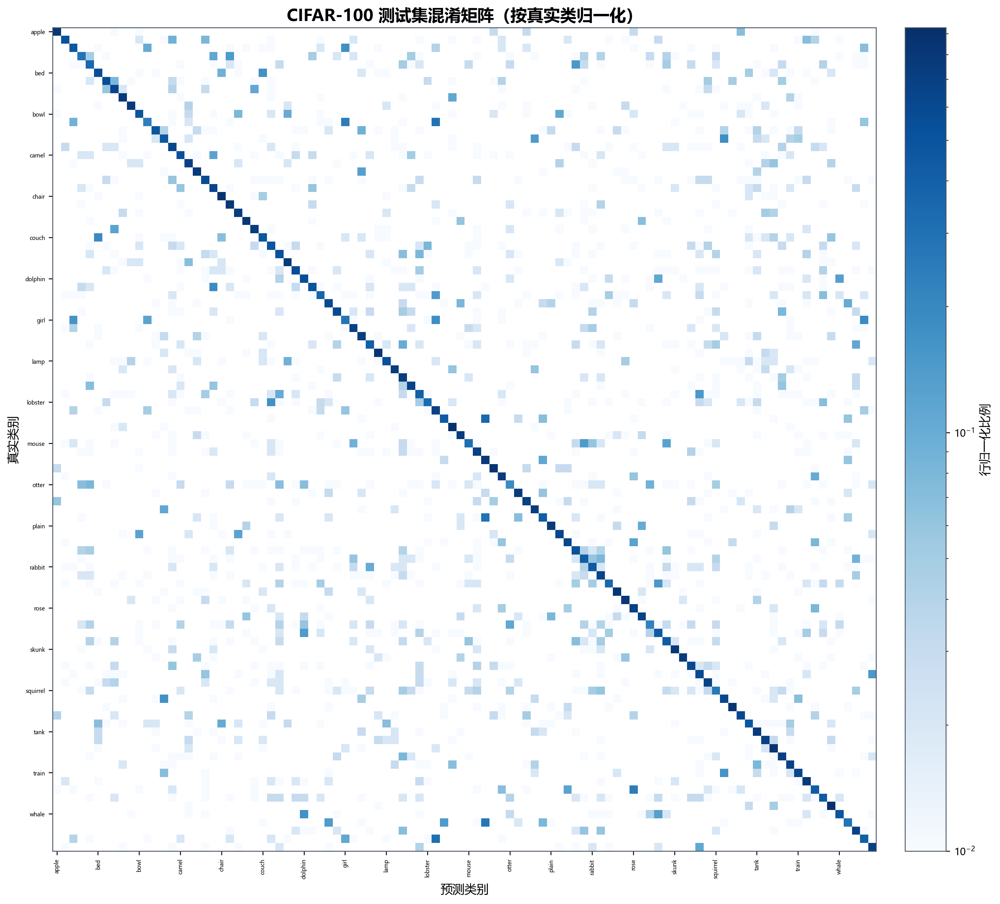

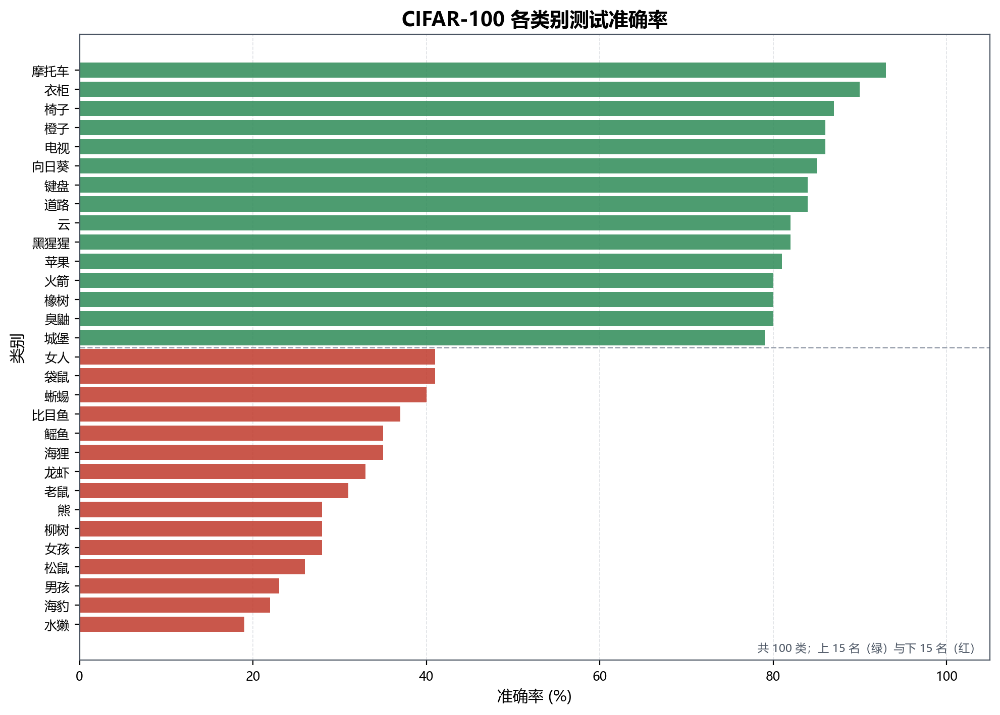

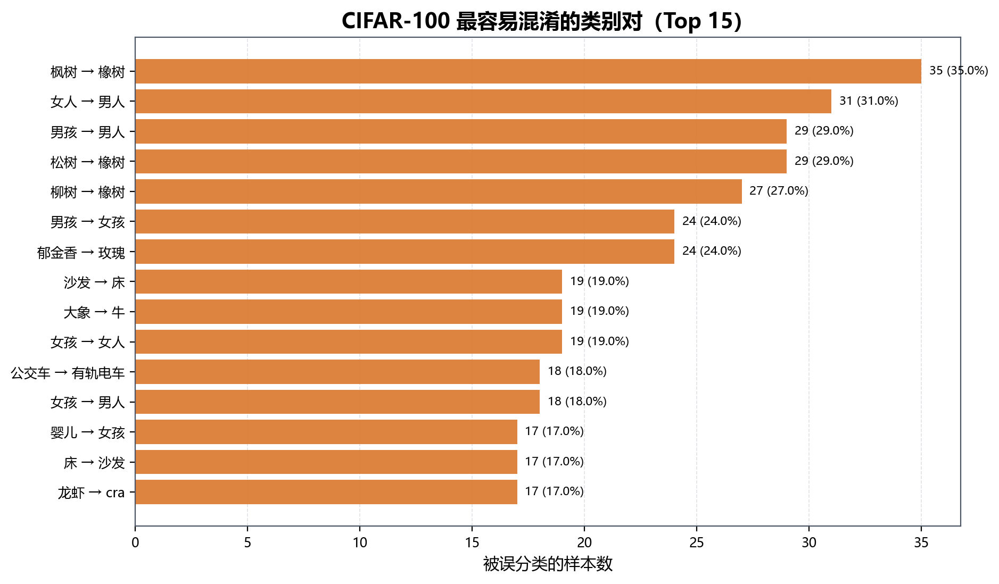

In [10]:
c100_metrics = evaluate_test(c100.trainer, bundles["cifar100"], METRICS_DIR)
save_predictions_csv(bundles["cifar100"], METRICS_DIR)
display(pd.DataFrame([c100_metrics]).T.rename(columns={0: "CIFAR-100"}))

cm100 = np.load(METRICS_DIR / "cifar100_confusion_matrix.npy")
p = vis.plot_confusion_matrix(cm100, spec100.class_names, FIG_DIR / "09_cifar100_confusion_matrix.png",
                              "CIFAR-100", normalize=True)
show(p, 1000)

report100 = pd.read_csv(METRICS_DIR / "cifar100_classification_report.csv")
p = vis.plot_per_class_accuracy(report100, FIG_DIR / "10_cifar100_per_class_accuracy.png", "CIFAR-100")
show(p, 950)

pairs100 = pd.read_csv(METRICS_DIR / "cifar100_top_confusions.csv")
p = vis.plot_top_confusions(pairs100, spec100.class_names_zh,
                            FIG_DIR / "11_cifar100_top_confusions.png", "CIFAR-100")
show(p, 950)

## 6. CNN 特征提取

对两个数据集的完整测试集（各 10,000 张）提取 512 维特征：

1. **主实验（冻结特征）**：使用同一份 ImageNet 预训练 ResNet18 Backbone，不进行任何微调，输入 Resize 到 224×224（与 ImageNet 预训练输入一致）；
2. **补充分析（微调特征）**：使用各自分类训练后的 Backbone，输入 96×96，观察“为分类优化的特征”与“通用预训练特征”在聚类上的差异。

特征矩阵保存为 `results/features/*.npz`，包含 `features`（10000×512）与 `labels`。

In [11]:
frozen_backbone = FeatureBackbone(pretrained=True)
print("冻结 ImageNet Backbone 已加载。")

feature_summary = {}
for name, b in bundles.items():
    print(f"\n>>> {b.spec.display_name}: 冻结特征 @ {FROZEN_FEATURE_SIZE}px")
    f, y = extract_features(
        frozen_backbone, b.images_test, b.labels_test, b.test_indices,
        FROZEN_FEATURE_SIZE, b.spec.task_id, batch_size=64, device=DEVICE,
        desc=f"{name}-frozen",
    )
    meta = {"dataset": name, "source": "frozen ImageNet ResNet18", "img_size": FROZEN_FEATURE_SIZE,
            "feature_dim": int(f.shape[1]), "n_samples": int(len(y))}
    save_feature_bundle(FEAT_DIR / f"{name}_test_frozen.npz", f, y, meta)
    feature_summary[f"{name}_frozen"] = meta

for name, result in [("cifar10", c10), ("cifar100", c100)]:
    b = bundles[name]
    print(f"\n>>> {b.spec.display_name}: 微调特征 @ {IMG_SIZE}px")
    f, y = extract_features(
        result.model.backbone, b.images_test, b.labels_test, b.test_indices,
        IMG_SIZE, b.spec.task_id, batch_size=64, device=DEVICE,
        desc=f"{name}-finetuned",
    )
    meta = {"dataset": name, "source": "fine-tuned ResNet18 backbone", "img_size": IMG_SIZE,
            "feature_dim": int(f.shape[1]), "n_samples": int(len(y))}
    save_feature_bundle(FEAT_DIR / f"{name}_test_finetuned.npz", f, y, meta)
    feature_summary[f"{name}_finetuned"] = meta

display(pd.DataFrame(feature_summary).T)
for key, meta in feature_summary.items():
    f, y, _ = load_feature_bundle(FEAT_DIR / f"{meta['dataset']}_test_{key.split('_')[1]}.npz")
    print(f"{key:20s} shape={f.shape}  L2-norm mean={np.linalg.norm(f, axis=1).mean():.3f}")
del frozen_backbone

冻结 ImageNet Backbone 已加载。

>>> CIFAR-10: 冻结特征 @ 224px


  cifar10-frozen: 1280/10000 images (21 img/s)


  cifar10-frozen: 2560/10000 images (21 img/s)


  cifar10-frozen: 3840/10000 images (21 img/s)


  cifar10-frozen: 5120/10000 images (21 img/s)


  cifar10-frozen: 6400/10000 images (21 img/s)


... (31 outputs left out)

cifar10_frozen       shape=(10000, 512)  L2-norm mean=27.731


cifar100_frozen      shape=(10000, 512)  L2-norm mean=26.593


cifar10_finetuned    shape=(10000, 512)  L2-norm mean=34.393


cifar100_finetuned   shape=(10000, 512)  L2-norm mean=35.279


## 7. K-Means 聚类

聚类直接调用 sklearn 的 `MiniBatchKMeans`，不实现任何 K-Means 算法，也不训练额外的深度聚类网络。流程：

1. 对特征做 L2 行归一化，降低特征幅值差异；
2. `MiniBatchKMeans(n_clusters=K, init="k-means++", batch_size=4096, n_init=10, max_iter=500, random_state=42)`；
3. 在完整 10,000 张测试集上得到簇标签；
4. 计算 ARI、NMI、轮廓系数（5,000 个分层样本）、簇纯度与匈牙利匹配准确率；
5. 用 PCA 与 t-SNE 将 5,000 个分层样本降到二维，分别按真实类别与聚类簇着色。

**指标含义**：

- **ARI**：调整兰德指数，衡量两个划分的一致性，随机划分为 0，完全一致为 1；
- **NMI**：归一化互信息，衡量聚类与真实标签共享的信息量；
- **Purity**：每个簇取多数真实类后的正确比例，容易随 K 增大而偏高，因此同时报告 ARI/NMI；
- **Silhouette**：簇内紧致度与簇间分离度的综合指标，范围约 [-1, 1]。


=== K-Means: cifar10 / frozen / K=10 ===
features=(10000, 512) preprocessing=l2


MiniBatchKMeans finished in 5.3s, inertia=2590.72


{
  "dataset": "cifar10",
  "feature_source": "frozen",
  "preprocessing": "l2",
  "k": 10,
  "n_samples": 10000,
  "feature_dim": 512,
  "algorithm": "MiniBatchKMeans (scikit-learn)",
  "batch_size": 4096,
  "n_init": 10,
  "max_iter": 500,
  "seed": 42,
  "ari": 0.3381994482941894,
  "nmi": 0.47962829741356827,
  "silhouette": 0.03792261704802513,
  "purity": 0.5527,
  "matched_accuracy": 0.5138,
  "inertia": 2590.72265625,
  "elapsed_sec": 5.35,
  "cluster_size_min": 560,
  "cluster_size_max": 1475,
  "cluster_size_mean": 1000.0,
  "cluster_size_std": 303.4125903781845,
  "empty_clusters": 0,
  "vis_sample_size": 5000,
  "tsne_computed": true
}
  computing t-SNE on 50 PCA components ...


,CIFAR-10 K=10
dataset,cifar10
feature_source,frozen
preprocessing,l2
k,10
n_samples,10000
feature_dim,512
algorithm,MiniBatchKMeans (scikit-learn)
batch_size,4096
n_init,10
max_iter,500


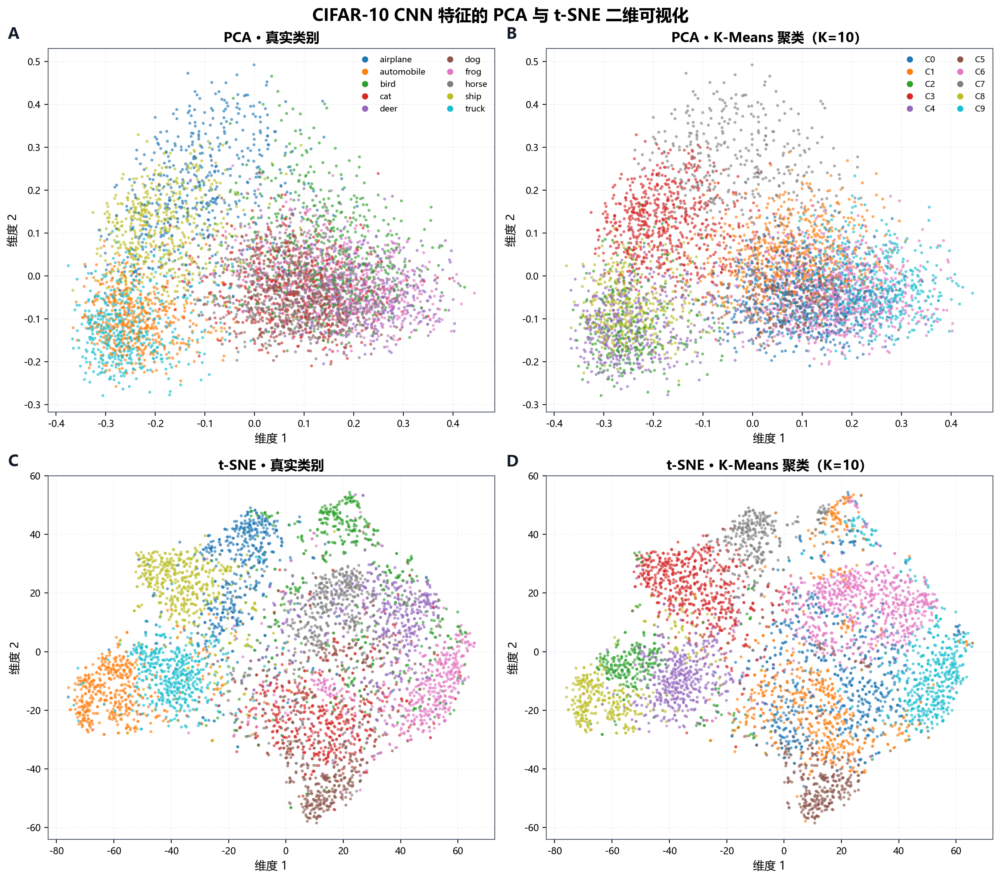

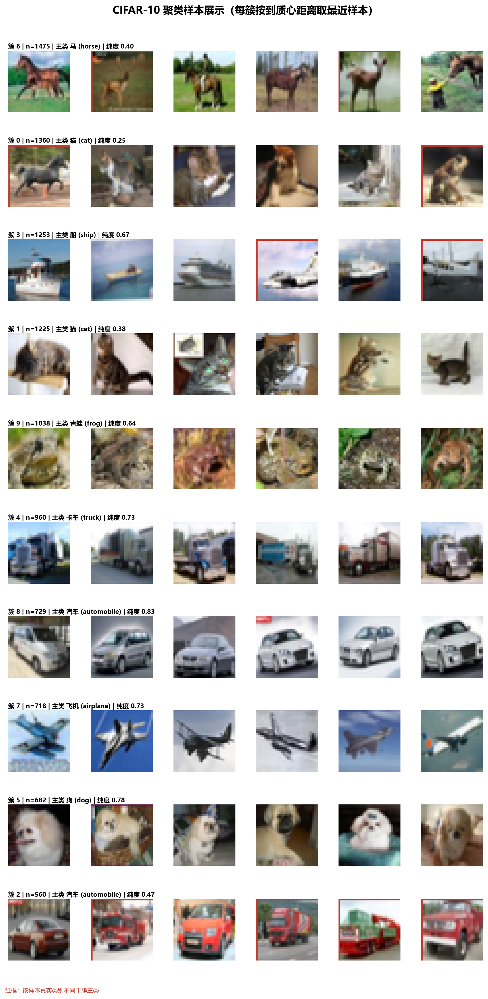

In [12]:
c10_cluster = run_clustering(
    "cifar10", FEAT_DIR / "cifar10_test_frozen.npz",
    METRICS_DIR / "cifar10_clustering.json", FEAT_DIR,
    k=10, feature_source="frozen", preprocessing="l2",
    seed=SEED, vis_sample_size=VIS_SAMPLE, run_tsne=True,
    class_names=spec10.class_names,
)
display(pd.DataFrame([c10_cluster]).T.rename(columns={0: "CIFAR-10 K=10"}))

p = vis.plot_pca_tsne(
    np.load(FEAT_DIR / "cifar10_frozen_pca2d.npy"),
    np.load(FEAT_DIR / "cifar10_frozen_tsne2d.npy"),
    np.load(FEAT_DIR / "cifar10_frozen_vis_labels.npy"),
    np.load(FEAT_DIR / "cifar10_frozen_vis_clusters.npy"),
    spec10.class_names, FIG_DIR / "12_cifar10_pca_tsne.png", "CIFAR-10", 10,
)
show(p, 1050)

assign10 = pd.read_csv(FEAT_DIR / "cifar10_frozen_cluster_assignments.csv")
p = vis.plot_cluster_gallery(
    bundles["cifar10"].images_test, bundles["cifar10"].labels_test,
    assign10["cluster"].values, assign10["distance_to_centroid"].values,
    spec10.class_names, spec10.class_names_zh,
    FIG_DIR / "13_cifar10_cluster_samples.png", "CIFAR-10", 10,
    max_clusters=10, n_images=6,
)
show(p, 1000)


=== K-Means: cifar100 / frozen / K=100 ===
features=(10000, 512) preprocessing=l2


MiniBatchKMeans finished in 55.0s, inertia=2442.60


{
  "dataset": "cifar100",
  "feature_source": "frozen",
  "preprocessing": "l2",
  "k": 100,
  "n_samples": 10000,
  "feature_dim": 512,
  "algorithm": "MiniBatchKMeans (scikit-learn)",
  "batch_size": 4096,
  "n_init": 10,
  "max_iter": 500,
  "seed": 42,
  "ari": 0.16160827899636832,
  "nmi": 0.4873753479359542,
  "silhouette": 0.02907772734761238,
  "purity": 0.3074,
  "matched_accuracy": 0.2909,
  "inertia": 2442.59521484375,
  "elapsed_sec": 55.0,
  "cluster_size_min": 4,
  "cluster_size_max": 172,
  "cluster_size_mean": 100.0,
  "cluster_size_std": 31.865655493022576,
  "empty_clusters": 0,
  "vis_sample_size": 5000,
  "tsne_computed": true
}
  computing t-SNE on 50 PCA components ...


,CIFAR-100 K=100
dataset,cifar100
feature_source,frozen
preprocessing,l2
k,100
n_samples,10000
feature_dim,512
algorithm,MiniBatchKMeans (scikit-learn)
batch_size,4096
n_init,10
max_iter,500


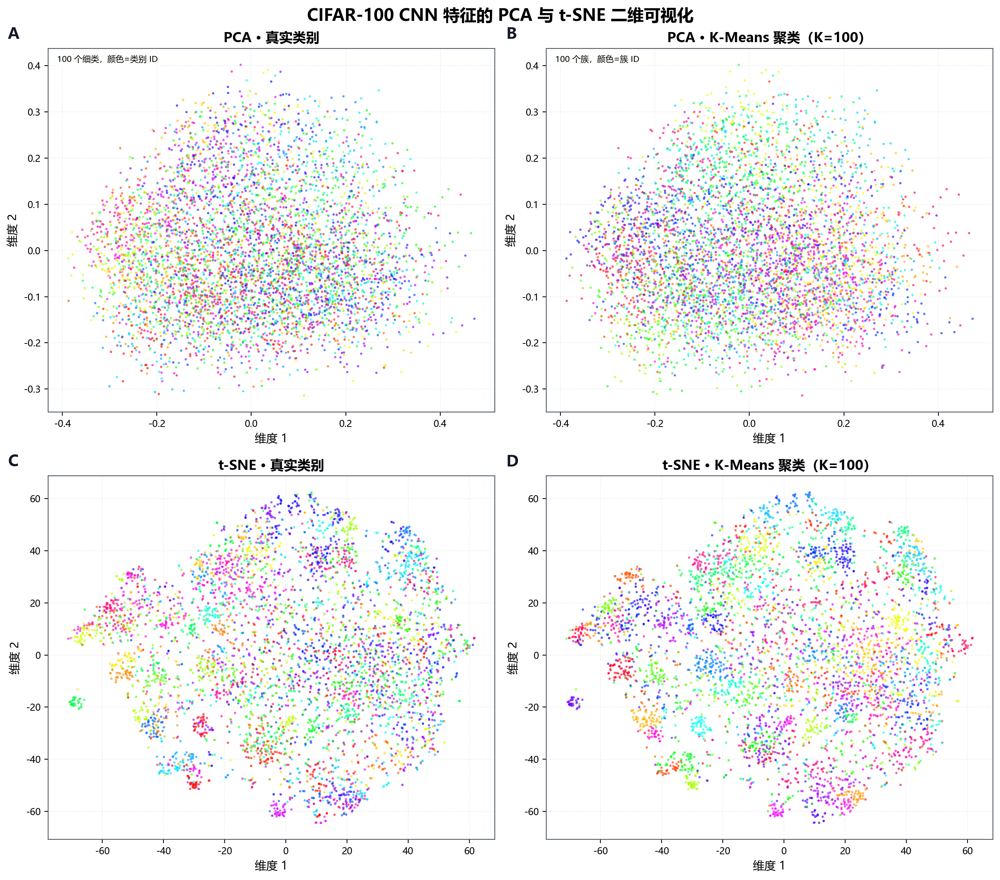

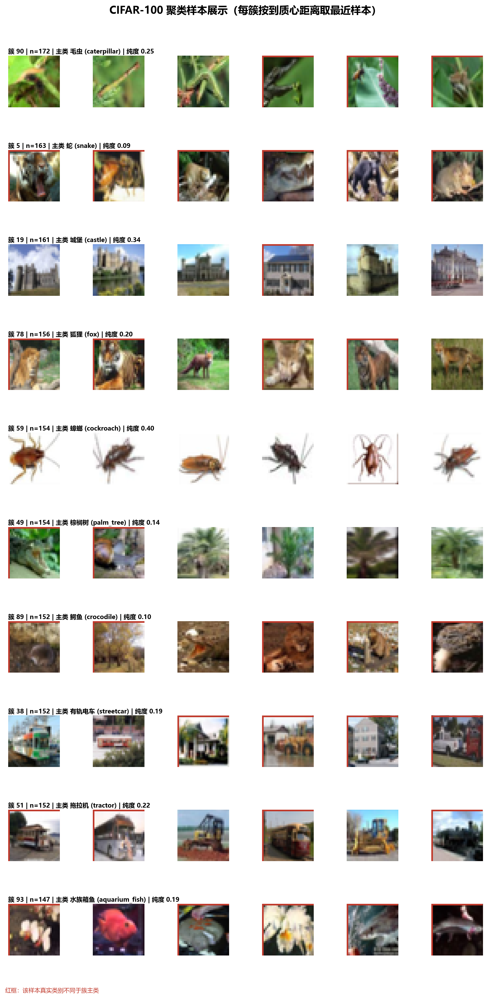

In [13]:
c100_cluster = run_clustering(
    "cifar100", FEAT_DIR / "cifar100_test_frozen.npz",
    METRICS_DIR / "cifar100_clustering.json", FEAT_DIR,
    k=100, feature_source="frozen", preprocessing="l2",
    seed=SEED, vis_sample_size=VIS_SAMPLE, run_tsne=True,
    class_names=spec100.class_names,
)
display(pd.DataFrame([c100_cluster]).T.rename(columns={0: "CIFAR-100 K=100"}))

p = vis.plot_pca_tsne(
    np.load(FEAT_DIR / "cifar100_frozen_pca2d.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_tsne2d.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_vis_labels.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_vis_clusters.npy"),
    spec100.class_names, FIG_DIR / "14_cifar100_pca_tsne.png", "CIFAR-100", 100,
)
show(p, 1050)

assign100 = pd.read_csv(FEAT_DIR / "cifar100_frozen_cluster_assignments.csv")
p = vis.plot_cluster_gallery(
    bundles["cifar100"].images_test, bundles["cifar100"].labels_test,
    assign100["cluster"].values, assign100["distance_to_centroid"].values,
    spec100.class_names, spec100.class_names_zh,
    FIG_DIR / "15_cifar100_cluster_samples.png", "CIFAR-100", 100,
    max_clusters=10, n_images=6,
)
show(p, 1000)

In [14]:
# 补充：微调特征上的聚类，用于分析“分类特征 vs 通用预训练特征”
ft_cluster = {}
for name, b, k in [("cifar10", bundles["cifar10"], 10), ("cifar100", bundles["cifar100"], 100)]:
    ft_cluster[name] = run_clustering(
        name, FEAT_DIR / f"{name}_test_finetuned.npz",
        METRICS_DIR / f"{name}_clustering_finetuned.json", FEAT_DIR,
        k=k, feature_source="finetuned", preprocessing="l2",
        seed=SEED, vis_sample_size=VIS_SAMPLE, run_tsne=False,
        class_names=b.spec.class_names,
    )

rows = []
for name, b in bundles.items():
    rows.append({
        "数据集": b.spec.display_name, "K": b.spec.num_classes,
        "特征": "冻结 ImageNet", "ARI": round((c10_cluster if name == "cifar10" else c100_cluster)["ari"], 4),
        "NMI": round((c10_cluster if name == "cifar10" else c100_cluster)["nmi"], 4),
        "Purity": round((c10_cluster if name == "cifar10" else c100_cluster)["purity"], 4),
    })
    rows.append({
        "数据集": b.spec.display_name, "K": b.spec.num_classes,
        "特征": "微调 Backbone", "ARI": round(ft_cluster[name]["ari"], 4),
        "NMI": round(ft_cluster[name]["nmi"], 4),
        "Purity": round(ft_cluster[name]["purity"], 4),
    })
ft_table = pd.DataFrame(rows)
display(ft_table)
ft_table.to_csv(METRICS_DIR / "clustering_feature_source_comparison.csv", index=False, encoding="utf-8-sig")


=== K-Means: cifar10 / finetuned / K=10 ===
features=(10000, 512) preprocessing=l2


MiniBatchKMeans finished in 5.0s, inertia=2685.81


{
  "dataset": "cifar10",
  "feature_source": "finetuned",
  "preprocessing": "l2",
  "k": 10,
  "n_samples": 10000,
  "feature_dim": 512,
  "algorithm": "MiniBatchKMeans (scikit-learn)",
  "batch_size": 4096,
  "n_init": 10,
  "max_iter": 500,
  "seed": 42,
  "ari": 0.749838551865134,
  "nmi": 0.7588096383604322,
  "silhouette": 0.23778964579105377,
  "purity": 0.8755,
  "matched_accuracy": 0.8755,
  "inertia": 2685.80859375,
  "elapsed_sec": 4.97,
  "cluster_size_min": 893,
  "cluster_size_max": 1075,
  "cluster_size_mean": 1000.0,
  "cluster_size_std": 66.7203117498712,
  "empty_clusters": 0,
  "vis_sample_size": 5000,
  "tsne_computed": false
}



=== K-Means: cifar100 / finetuned / K=100 ===
features=(10000, 512) preprocessing=l2


MiniBatchKMeans finished in 56.8s, inertia=2987.45


{
  "dataset": "cifar100",
  "feature_source": "finetuned",
  "preprocessing": "l2",
  "k": 100,
  "n_samples": 10000,
  "feature_dim": 512,
  "algorithm": "MiniBatchKMeans (scikit-learn)",
  "batch_size": 4096,
  "n_init": 10,
  "max_iter": 500,
  "seed": 42,
  "ari": 0.33162184110693593,
  "nmi": 0.6250782157694663,
  "silhouette": 0.09819664806127548,
  "purity": 0.4791,
  "matched_accuracy": 0.4654,
  "inertia": 2987.451171875,
  "elapsed_sec": 56.76,
  "cluster_size_min": 2,
  "cluster_size_max": 263,
  "cluster_size_mean": 100.0,
  "cluster_size_std": 36.037202999123004,
  "empty_clusters": 0,
  "vis_sample_size": 5000,
  "tsne_computed": false
}


,数据集,K,特征,ARI,NMI,Purity
0,CIFAR-10,10,冻结 ImageNet,0.3382,0.4796,0.5527
1,CIFAR-10,10,微调 Backbone,0.7498,0.7588,0.8755
2,CIFAR-100,100,冻结 ImageNet,0.1616,0.4874,0.3074
3,CIFAR-100,100,微调 Backbone,0.3316,0.6251,0.4791


## 8. CIFAR-10 与 CIFAR-100 对比分析

从四个角度比较：

1. **数据特点**：10 类 vs 100 类；每类训练/测试样本数相差 10 倍；100 类任务中类间差异更细（如不同树种、鱼、花）；
2. **分类性能**：Accuracy、Top-3/Top-5、Macro F1、单类准确率分布、混淆矩阵；
3. **聚类性能**：ARI、NMI、Purity、Silhouette；
4. **特征分布**：PCA / t-SNE 的簇分离程度。

下面的综合指标图与表格均由本次运行的 JSON/CSV 结果直接生成。

,CIFAR-10,CIFAR-100
指标,,
类别数,10.0000,100.0000
随机猜测 Accuracy,0.1000,0.0100
测试 Accuracy,0.8754,0.6008
Top-3 Accuracy,0.9802,0.8140
Top-5 Accuracy,0.9956,0.8851
Macro F1,0.8742,0.5949
聚类 ARI,0.3382,0.1616
聚类 NMI,0.4796,0.4874
聚类 Purity,0.5527,0.3074


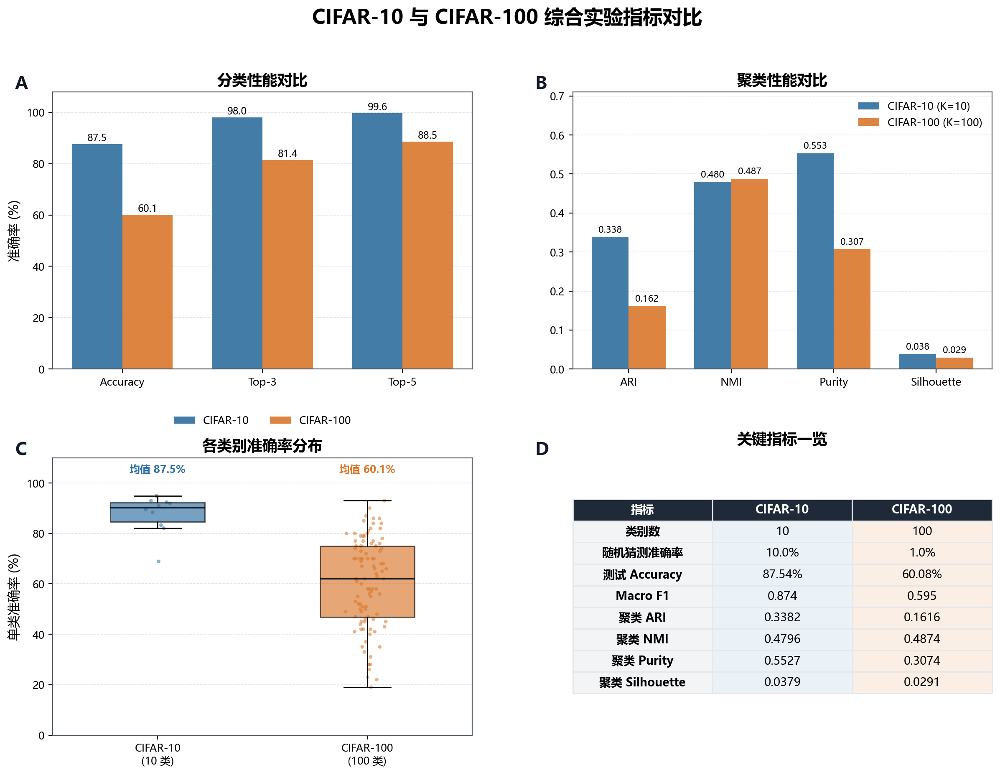

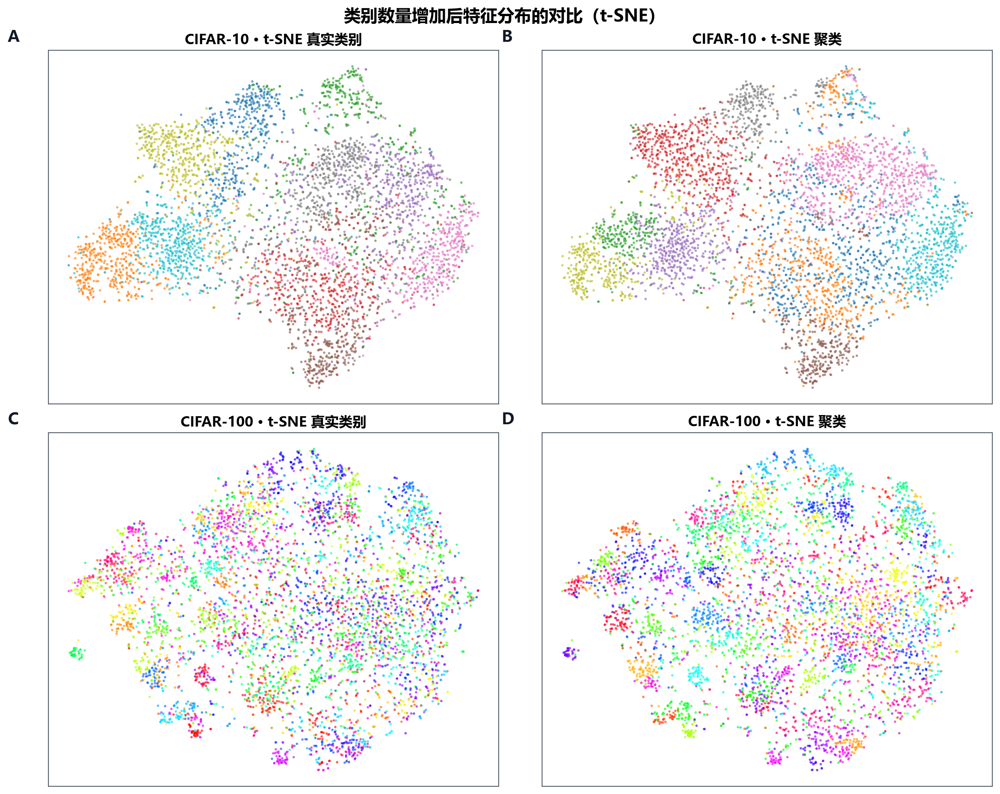

In [15]:
comparison = pd.DataFrame([
    {"指标": "类别数", "CIFAR-10": 10, "CIFAR-100": 100},
    {"指标": "随机猜测 Accuracy", "CIFAR-10": round(c10_metrics["chance_level"], 4),
     "CIFAR-100": round(c100_metrics["chance_level"], 4)},
    {"指标": "测试 Accuracy", "CIFAR-10": round(c10_metrics["accuracy"], 4),
     "CIFAR-100": round(c100_metrics["accuracy"], 4)},
    {"指标": "Top-3 Accuracy", "CIFAR-10": round(c10_metrics["top3_accuracy"], 4),
     "CIFAR-100": round(c100_metrics["top3_accuracy"], 4)},
    {"指标": "Top-5 Accuracy", "CIFAR-10": round(c10_metrics["top5_accuracy"], 4),
     "CIFAR-100": round(c100_metrics["top5_accuracy"], 4)},
    {"指标": "Macro F1", "CIFAR-10": round(c10_metrics["macro_f1"], 4),
     "CIFAR-100": round(c100_metrics["macro_f1"], 4)},
    {"指标": "聚类 ARI", "CIFAR-10": round(c10_cluster["ari"], 4),
     "CIFAR-100": round(c100_cluster["ari"], 4)},
    {"指标": "聚类 NMI", "CIFAR-10": round(c10_cluster["nmi"], 4),
     "CIFAR-100": round(c100_cluster["nmi"], 4)},
    {"指标": "聚类 Purity", "CIFAR-10": round(c10_cluster["purity"], 4),
     "CIFAR-100": round(c100_cluster["purity"], 4)},
    {"指标": "聚类 Silhouette", "CIFAR-10": round(c10_cluster["silhouette"], 4),
     "CIFAR-100": round(c100_cluster["silhouette"], 4)},
])
display(comparison.set_index("指标"))
comparison.to_csv(METRICS_DIR / "comparison.csv", index=False, encoding="utf-8-sig")

summary = {
    "classification": {"cifar10": c10_metrics, "cifar100": c100_metrics},
    "clustering": {"cifar10": c10_cluster, "cifar100": c100_cluster},
    "clustering_finetuned": ft_cluster,
}
(METRICS_DIR / "comparison.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2),
                                              encoding="utf-8")

p = vis.plot_comparison_dashboard(c10_metrics, c100_metrics, c10_cluster, c100_cluster,
                                  report10, report100, FIG_DIR / "16_comparison_dashboard.png")
show(p, 1150)

p = vis.plot_comparison_tsne(
    np.load(FEAT_DIR / "cifar10_frozen_tsne2d.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_tsne2d.npy"),
    np.load(FEAT_DIR / "cifar10_frozen_vis_labels.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_vis_labels.npy"),
    np.load(FEAT_DIR / "cifar10_frozen_vis_clusters.npy"),
    np.load(FEAT_DIR / "cifar100_frozen_vis_clusters.npy"),
    FIG_DIR / "17_comparison_tsne.png",
)
show(p, 1050)

In [16]:
# 定量描述差异（全部由本次实际指标计算）
acc_gap = (c10_metrics["accuracy"] - c100_metrics["accuracy"]) * 100
ari_gap = c10_cluster["ari"] - c100_cluster["ari"]
nmi_gap = c10_cluster["nmi"] - c100_cluster["nmi"]
rel10 = c10_metrics["accuracy"] / c10_metrics["chance_level"]
rel100 = c100_metrics["accuracy"] / c100_metrics["chance_level"]

text = f'''
### 主要观察

- **分类**：CIFAR-10 测试 Accuracy 为 **{c10_metrics["accuracy"]*100:.2f}%**，CIFAR-100 为 **{c100_metrics["accuracy"]*100:.2f}%**，相差 **{acc_gap:.2f} 个百分点**；两者分别为随机猜测的 **{rel10:.1f} 倍**与 **{rel100:.1f} 倍**。
- **聚类**：CIFAR-10 的 ARI / NMI 为 **{c10_cluster["ari"]:.4f} / {c10_cluster["nmi"]:.4f}**，CIFAR-100 为 **{c100_cluster["ari"]:.4f} / {c100_cluster["nmi"]:.4f}**；ARI 相差 **{ari_gap:.4f}**，NMI 相差 **{nmi_gap:.4f}**。
- **类别数的影响**：在训练样本量相同（5,000 张）的条件下，类别数从 10 增加到 100，平均每类可用样本从 500 张降到 50 张，类间边界更细，分类与聚类的难度同时上升。
- **混淆结构**：CIFAR-10 的错误主要集中在猫/狗、鹿/马、鸟/青蛙等视觉相似类别；CIFAR-100 的 100×100 混淆矩阵更分散，Top 混淆对可通过 `results/metrics/cifar100_top_confusions.csv` 查看。
- **聚类与分类的差距**：K-Means 只使用 512 维特征和欧氏距离，不使用标签；其 ARI 明显低于有监督分类 Accuracy，说明无监督聚类仍难以恢复细粒度语义类别。
'''
display(Markdown(text))
(METRICS_DIR / "conclusions.md").write_text(text, encoding="utf-8")


### 主要观察

- **分类**：CIFAR-10 测试 Accuracy 为 **87.54%**，CIFAR-100 为 **60.08%**，相差 **27.46 个百分点**；两者分别为随机猜测的 **8.8 倍**与 **60.1 倍**。
- **聚类**：CIFAR-10 的 ARI / NMI 为 **0.3382 / 0.4796**，CIFAR-100 为 **0.1616 / 0.4874**；ARI 相差 **0.1766**，NMI 相差 **-0.0077**。
- **类别数的影响**：在训练样本量相同（5,000 张）的条件下，类别数从 10 增加到 100，平均每类可用样本从 500 张降到 50 张，类间边界更细，分类与聚类的难度同时上升。
- **混淆结构**：CIFAR-10 的错误主要集中在猫/狗、鹿/马、鸟/青蛙等视觉相似类别；CIFAR-100 的 100×100 混淆矩阵更分散，Top 混淆对可通过 `results/metrics/cifar100_top_confusions.csv` 查看。
- **聚类与分类的差距**：K-Means 只使用 512 维特征和欧氏距离，不使用标签；其 ARI 明显低于有监督分类 Accuracy，说明无监督聚类仍难以恢复细粒度语义类别。


575

## 9. 实验结论与局限

**结论**

1. 同一 ImageNet 预训练 ResNet18 Backbone 可以通过更换分类头，同时服务 CIFAR-10 与 CIFAR-100；
2. 在相同训练样本量下，CIFAR-10 的分类与聚类指标均优于 CIFAR-100，类别数量与类间细粒度是主要影响因素；
3. 微调后的 Backbone 特征更利于分类，但聚类表现不一定同步提升，说明“判别性特征”和“聚类友好特征”并不完全一致；
4. Hugging Face Trainer 与 sklearn MiniBatchKMeans 足以完成本作业的全部训练与聚类要求，无需手写训练循环或 K-Means。

**局限**

- CPU 环境下仅训练 3 个 epoch，且使用 5,000 张分层训练子集，绝对精度低于 GPU 上全量长训练的结果；
- 输入尺寸 96×96 是计算量与特征质量之间的折中，未系统搜索 128/160/224；
- 聚类使用冻结的 ImageNet 特征，未进行度量学习或深度聚类；
- t-SNE 仅用于二维可视化，其坐标不保留全局距离，不能替代定量指标。

In [17]:
# 交付文件清单
items = []
for folder in ["checkpoints", "results/metrics", "results/figures", "results/features"]:
    for p in sorted((ROOT / folder).rglob("*")):
        if p.is_file() and "_smoke" not in str(p):
            items.append({"文件": str(p.relative_to(ROOT)), "大小(MB)": round(p.stat().st_size/1e6, 3)})
files = pd.DataFrame(items)
print(f"共 {len(files)} 个结果文件，总大小 {files['大小(MB)'].sum():.1f} MB")
display(files.tail(30))

共 88 个结果文件，总大小 227.1 MB


,文件,大小(MB)
58,results\features\cifar100_finetuned_vis_cluste...,0.040
59,results\features\cifar100_finetuned_vis_labels...,0.040
60,results\features\cifar100_finetuned_vis_sample...,0.040
61,results\features\cifar100_frozen_cluster_assig...,0.295
62,results\features\cifar100_frozen_cluster_cente...,0.205
63,results\features\cifar100_frozen_cluster_label...,0.080
64,results\features\cifar100_frozen_pca2d.npy,0.040
65,results\features\cifar100_frozen_tsne2d.npy,0.040
66,results\features\cifar100_frozen_vis_clusters.npy,0.040
67,results\features\cifar100_frozen_vis_labels.npy,0.040
